In [90]:

import os
import pandas as pd

# Automatically locate the uploaded CSV file
matches = []

for root, dirs, files in os.walk("/"):
    dirs[:] = [d for d in dirs if d not in [
        "proc", "sys", "dev", "usr", "lib", "lib64"
    ]]
    if "StudentsPerformance.csv" in files:
        matches.append(os.path.join(root, "StudentsPerformance.csv"))

if matches:
    csv_path = matches[0]
    df = pd.read_csv(csv_path)

    print("Dataset loaded successfully!")
    print("File location:", csv_path)
    print("Dataset shape:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())
    print("\nFirst five records:")
    display(df.head())
else:
    print("CSV file not found. Please upload it again using the Files panel.")


Dataset loaded successfully!
File location: /StudentsPerformance.csv
Dataset shape: (1000, 8)

Column names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

First five records:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [91]:

# STATISTICAL ANALYSIS USING NUMPY AND PANDAS

import numpy as np

print("=" * 60)
print("STATISTICAL ANALYSIS")
print("=" * 60)

for col in score_columns:
    scores = df[col].to_numpy()

    print(f"\n{col.title()}")
    print("Mean:", round(np.mean(scores), 2))
    print("Median:", round(np.median(scores), 2))
    print("Standard Deviation:", round(np.std(scores), 2))
    print("Minimum:", np.min(scores))
    print("Maximum:", np.max(scores))

print("\nSubject-wise Average Scores:")

subject_average = df[score_columns].mean()
subject_average.index = ["Math", "Reading", "Writing"]

display(subject_average.round(2).to_frame("Average Score"))


STATISTICAL ANALYSIS

Math Score
Mean: 66.09
Median: 66.0
Standard Deviation: 15.16
Minimum: 0
Maximum: 100

Reading Score
Mean: 69.17
Median: 70.0
Standard Deviation: 14.59
Minimum: 17
Maximum: 100

Writing Score
Mean: 68.05
Median: 69.0
Standard Deviation: 15.19
Minimum: 10
Maximum: 100

Subject-wise Average Scores:


,Average Score
Math,66.09
Reading,69.17
Writing,68.05


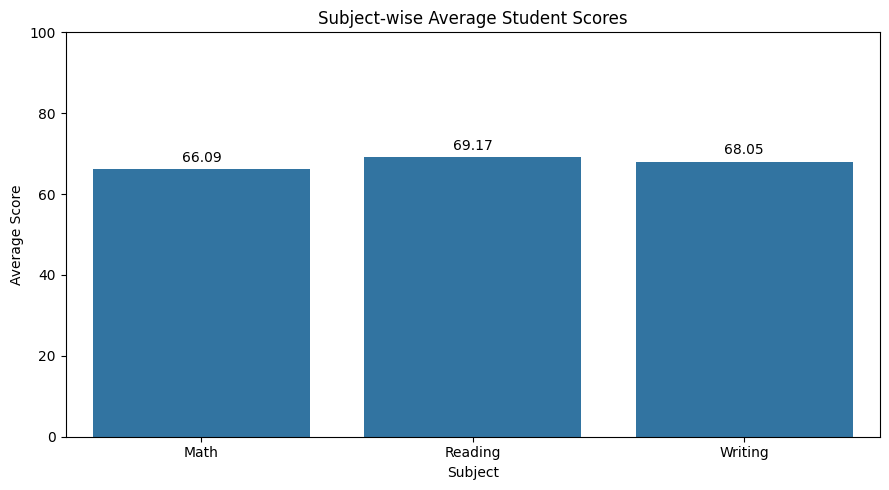

In [92]:

# GRAPH 1: SUBJECT-WISE AVERAGE SCORES

subject_average = df[
    ["math score", "reading score", "writing score"]
].mean()

subject_average.index = ["Math", "Reading", "Writing"]

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=subject_average.index,
    y=subject_average.values
)

plt.title("Subject-wise Average Student Scores")
plt.xlabel("Subject")
plt.ylabel("Average Score")
plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()


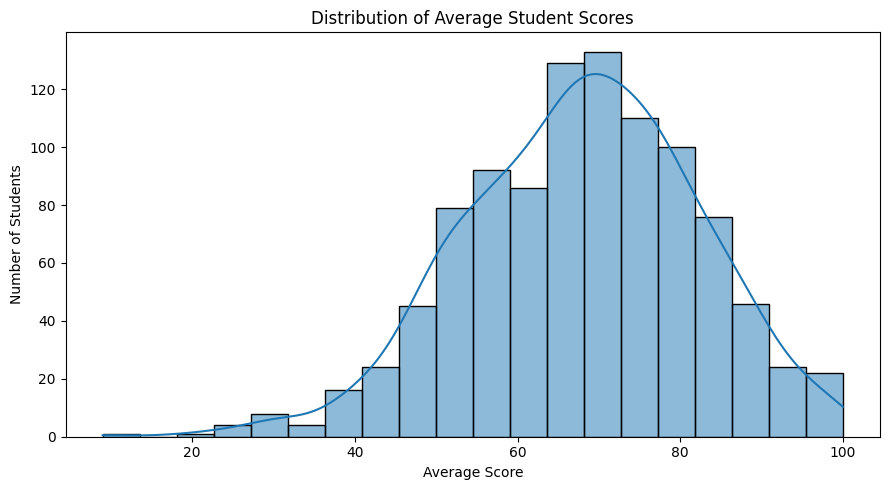

Average score column created successfully.
Overall average: 67.77


In [93]:

# GRAPH 2: DISTRIBUTION OF AVERAGE STUDENT SCORES

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the score columns exist
score_columns = ["math score", "reading score", "writing score"]

# Create average_score directly from the actual marks
df["average_score"] = df[score_columns].mean(axis=1)

# Draw the histogram
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="average_score",
    bins=20,
    kde=True
)

plt.title("Distribution of Average Student Scores")
plt.xlabel("Average Score")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

print("Average score column created successfully.")
print("Overall average:", round(df["average_score"].mean(), 2))


Gender-wise Average Scores:


,Math,Reading,Writing
gender,,,
female,63.63,72.61,72.47
male,68.73,65.47,63.31


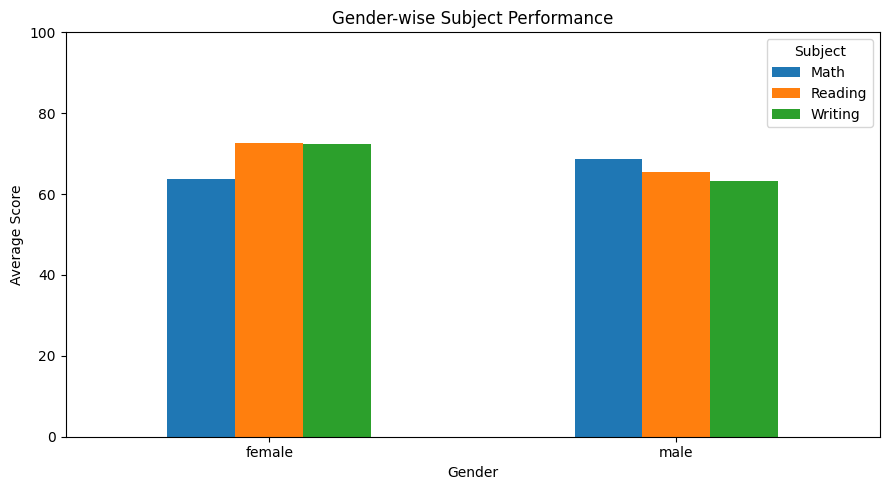

In [94]:

# GRAPH 3: GENDER-WISE SUBJECT PERFORMANCE

import matplotlib.pyplot as plt
import seaborn as sns

gender_performance = df.groupby("gender")[
    ["math score", "reading score", "writing score"]
].mean()

gender_performance.columns = ["Math", "Reading", "Writing"]

print("Gender-wise Average Scores:")
display(gender_performance.round(2))

ax = gender_performance.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Gender-wise Subject Performance")
plt.xlabel("Gender")
plt.ylabel("Average Score")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()


Category-wise Average Scores:


,Math,Reading,Writing
race/ethnicity,,,
group A,61.63,64.67,62.67
group B,63.45,67.35,65.60
group C,64.46,69.10,67.83
group D,67.36,70.03,70.15
group E,73.82,73.03,71.41


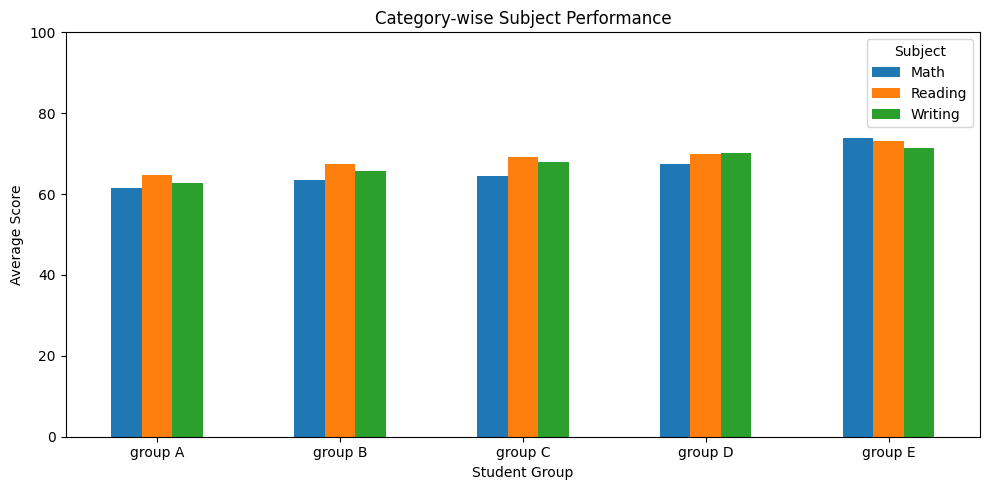

In [95]:

# GRAPH 4: CATEGORY-WISE PERFORMANCE

category_performance = df.groupby("race/ethnicity")[
    ["math score", "reading score", "writing score"]
].mean()

category_performance.columns = ["Math", "Reading", "Writing"]

print("Category-wise Average Scores:")
display(category_performance.round(2))

category_performance.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Category-wise Subject Performance")
plt.xlabel("Student Group")
plt.ylabel("Average Score")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()


Correlation Matrix:


,math score,reading score,writing score,average_score
math score,1.00,0.82,0.80,0.92
reading score,0.82,1.00,0.95,0.97
writing score,0.80,0.95,1.00,0.97
average_score,0.92,0.97,0.97,1.00


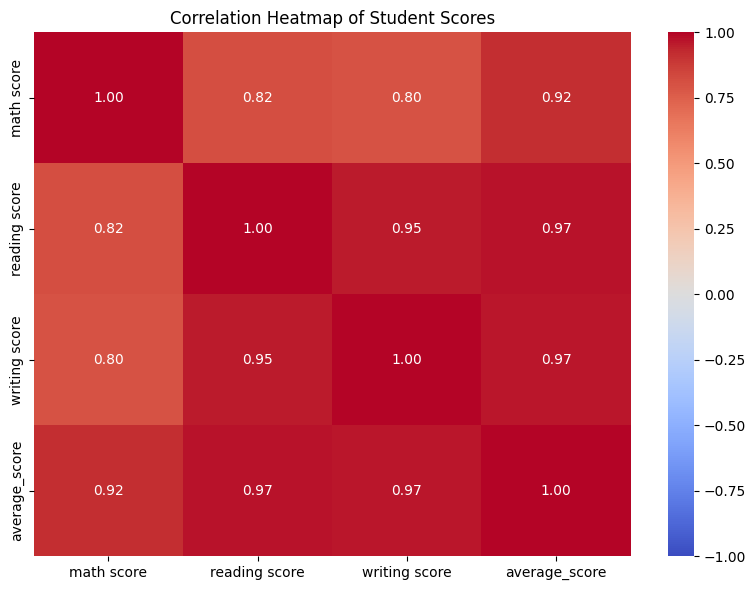

In [96]:

# GRAPH 5: CORRELATION HEATMAP

import seaborn as sns
import matplotlib.pyplot as plt

correlation_columns = [
    "math score",
    "reading score",
    "writing score",
    "average_score"
]

correlation = df[correlation_columns].corr()

print("Correlation Matrix:")
display(correlation.round(2))

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Student Scores")
plt.tight_layout()
plt.show()


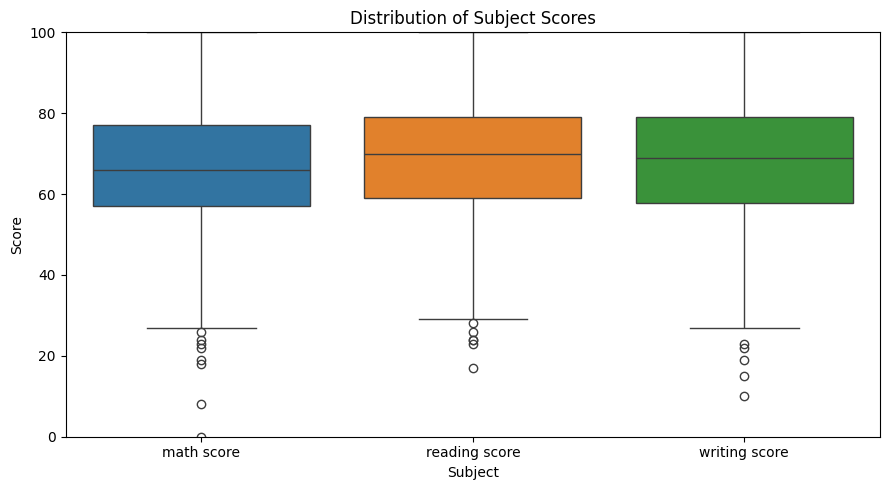

In [97]:

# GRAPH 6: DISTRIBUTION OF SUBJECT SCORES

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df[
        ["math score", "reading score", "writing score"]
    ]
)

plt.title("Distribution of Subject Scores")
plt.xlabel("Subject")
plt.ylabel("Score")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


In [98]:

# TOP 10 STUDENTS BY AVERAGE SCORE

import pandas as pd
from IPython.display import display

# Recalculate total and average scores
score_columns = [
    "math score",
    "reading score",
    "writing score"
]

df["total_score"] = df[score_columns].sum(axis=1)

df["average_score"] = (
    df[score_columns].mean(axis=1).round(2)
)

# Select the top 10 records
top_students = df.sort_values(
    by="average_score",
    ascending=False
).head(10)

print("Top 10 Students by Average Score:")

display(
    top_students[
        [
            "gender",
            "math score",
            "reading score",
            "writing score",
            "total_score",
            "average_score"
        ]
    ].reset_index(drop=True)
)


Top 10 Students by Average Score:


,gender,math score,reading score,writing score,total_score,average_score
0,male,100,100,100,300,100.00
1,female,100,100,100,300,100.00
2,female,100,100,100,300,100.00
3,female,99,100,100,299,99.67
4,female,98,100,99,297,99.00
5,female,97,100,100,297,99.00
6,female,96,100,100,296,98.67
7,male,100,97,99,296,98.67
8,female,94,99,100,293,97.67
9,female,93,100,100,293,97.67


In [99]:

# FINAL PROJECT SUMMARY

print("=" * 55)
print("STUDENT PERFORMANCE DATA ANALYSIS")
print("=" * 55)

print("Total Students:", len(df))
print("Average Math Score:", round(df["math score"].mean(), 2))
print("Average Reading Score:", round(df["reading score"].mean(), 2))
print("Average Writing Score:", round(df["writing score"].mean(), 2))
print("Overall Average Score:", round(df["average_score"].mean(), 2))
print("Highest Average Score:", round(df["average_score"].max(), 2))
print("Lowest Average Score:", round(df["average_score"].min(), 2))

subject_means = df[
    ["math score", "reading score", "writing score"]
].mean()

print("\nBest Performing Subject:", subject_means.idxmax())
print("Lowest Performing Subject:", subject_means.idxmin())

print("\nAnalysis completed successfully!")


STUDENT PERFORMANCE DATA ANALYSIS
Total Students: 1000
Average Math Score: 66.09
Average Reading Score: 69.17
Average Writing Score: 68.05
Overall Average Score: 67.77
Highest Average Score: 100.0
Lowest Average Score: 9.0

Best Performing Subject: reading score
Lowest Performing Subject: math score

Analysis completed successfully!


In [100]:

# FINAL PROJECT VALIDATION

print("PROJECT: STUDENT PERFORMANCE DATA ANALYSIS")
print("-" * 50)
print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

print("\nAvailable analysis columns:")
print(df.columns.tolist())

print("\nFinal dataset preview:")
display(df.head())

print("\nProject validation completed.")


PROJECT: STUDENT PERFORMANCE DATA ANALYSIS
--------------------------------------------------
Total records: 1000
Total columns: 10
Missing values: 0
Duplicate records: 0

Available analysis columns:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score', 'average_score', 'total_score']

Final dataset preview:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average_score,total_score
0,female,group B,bachelor's degree,standard,none,72,72,74,72.67,218
1,female,group C,some college,standard,completed,69,90,88,82.33,247
2,female,group B,master's degree,standard,none,90,95,93,92.67,278
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.33,148
4,male,group C,some college,standard,none,76,78,75,76.33,229



Project validation completed.


In [101]:

# DATA CLEANING AND PREPROCESSING

print("=" * 60)
print("DATA CLEANING")
print("=" * 60)

# Check missing values
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records Before Cleaning:")
print(df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates().copy()

# Identify numerical columns
score_columns = [
    "math score",
    "reading score",
    "writing score"
]

# Convert scores to numeric values
for col in score_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

# Handle missing categorical values
categorical_columns = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

for col in categorical_columns:
    df[col] = df[col].fillna("Unknown").astype(str).str.strip()

# Create total and average score columns
df["total_score"] = df[score_columns].sum(axis=1)
df["average_score"] = df[score_columns].mean(axis=1).round(2)

# Display cleaning results
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Records After Cleaning:")
print(df.duplicated().sum())

print("\nDataset Shape After Cleaning:", df.shape)

print("\nCleaned Dataset:")
display(df.head())


DATA CLEANING

Missing Values Before Cleaning:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
average_score                  0
total_score                    0
dtype: int64

Duplicate Records Before Cleaning:
0

Missing Values After Cleaning:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
average_score                  0
total_score                    0
dtype: int64

Duplicate Records After Cleaning:
0

Dataset Shape After Cleaning: (1000, 10)

Cleaned Dataset:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average_score,total_score
0,female,group B,bachelor's degree,standard,none,72,72,74,72.67,218
1,female,group C,some college,standard,completed,69,90,88,82.33,247
2,female,group B,master's degree,standard,none,90,95,93,92.67,278
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.33,148
4,male,group C,some college,standard,none,76,78,75,76.33,229
